In [ ]:
# Импортируем библиотеки

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Чтение и отображение данных

df = pd.read_excel("/Dry_Bean_Dataset.xlsx")
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:
print("Размерность датасета: ", df.shape)
print("+"*50)
df.info()
print("+"*50)
print("Классы:", df["Class"].unique())

Размерность датасета:  (13611, 17)
++++++++++++++++++++++++++++++++++++++++++++++++++
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     1

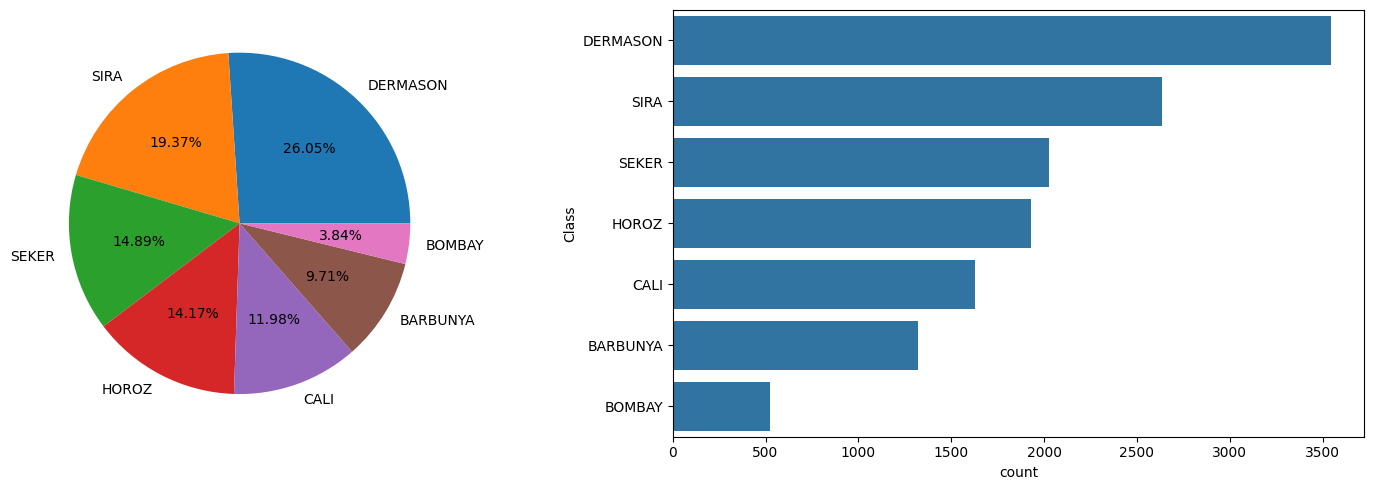

In [ ]:
# Рассмотрим как распределены наши признаки

count_class_df=df["Class"].value_counts().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].pie(labels=count_class_df["Class"], x=count_class_df["count"], autopct="%.2f%%")
sns.barplot(data=count_class_df, y="Class", x="count", ax=ax[1])
plt.tight_layout()
plt.show()

In [ ]:
# Данные не совсем сбалансированные
count_class_df

,Class,count
0,DERMASON,3546
1,SIRA,2636
2,SEKER,2027
3,HOROZ,1928
4,CALI,1630
5,BARBUNYA,1322
6,BOMBAY,522


In [ ]:
df.drop("Class", axis=1).describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


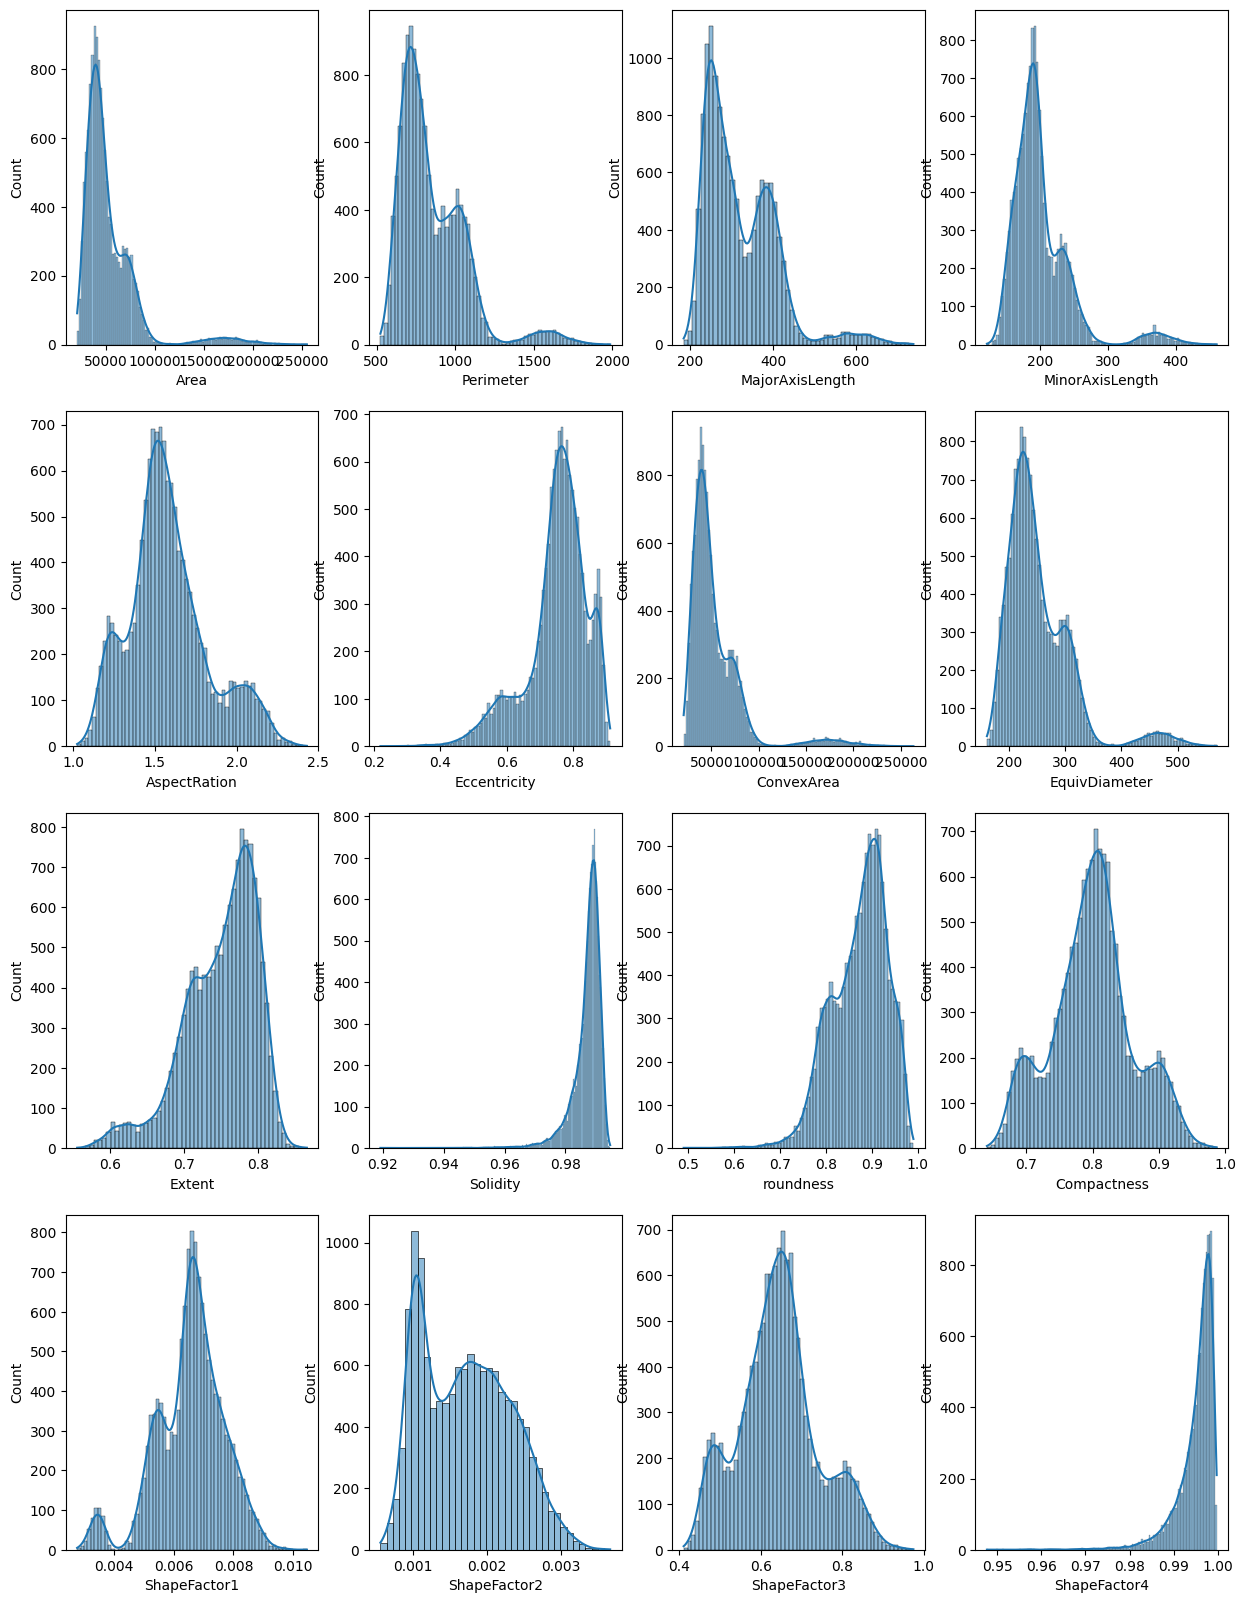

In [ ]:
# Некоторые графики из этих признаков смещены вправо или влево
# Некоторые графики из них имеют бимодальный или мультимодальный характер, поскольку демонстрируют несколько пиков

fig, ax=plt.subplots(4, 4, figsize=(15,20))
ax=ax.flatten()
i=0
for col in df.columns[df.columns!='Class']:
    sns.histplot(data=df, x=col, ax=ax[i], kde=True)
    i+=1

In [ ]:
# Удаляем дубликаты с Датасета
df.drop_duplicates(inplace=True, keep="first")

In [ ]:
df

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


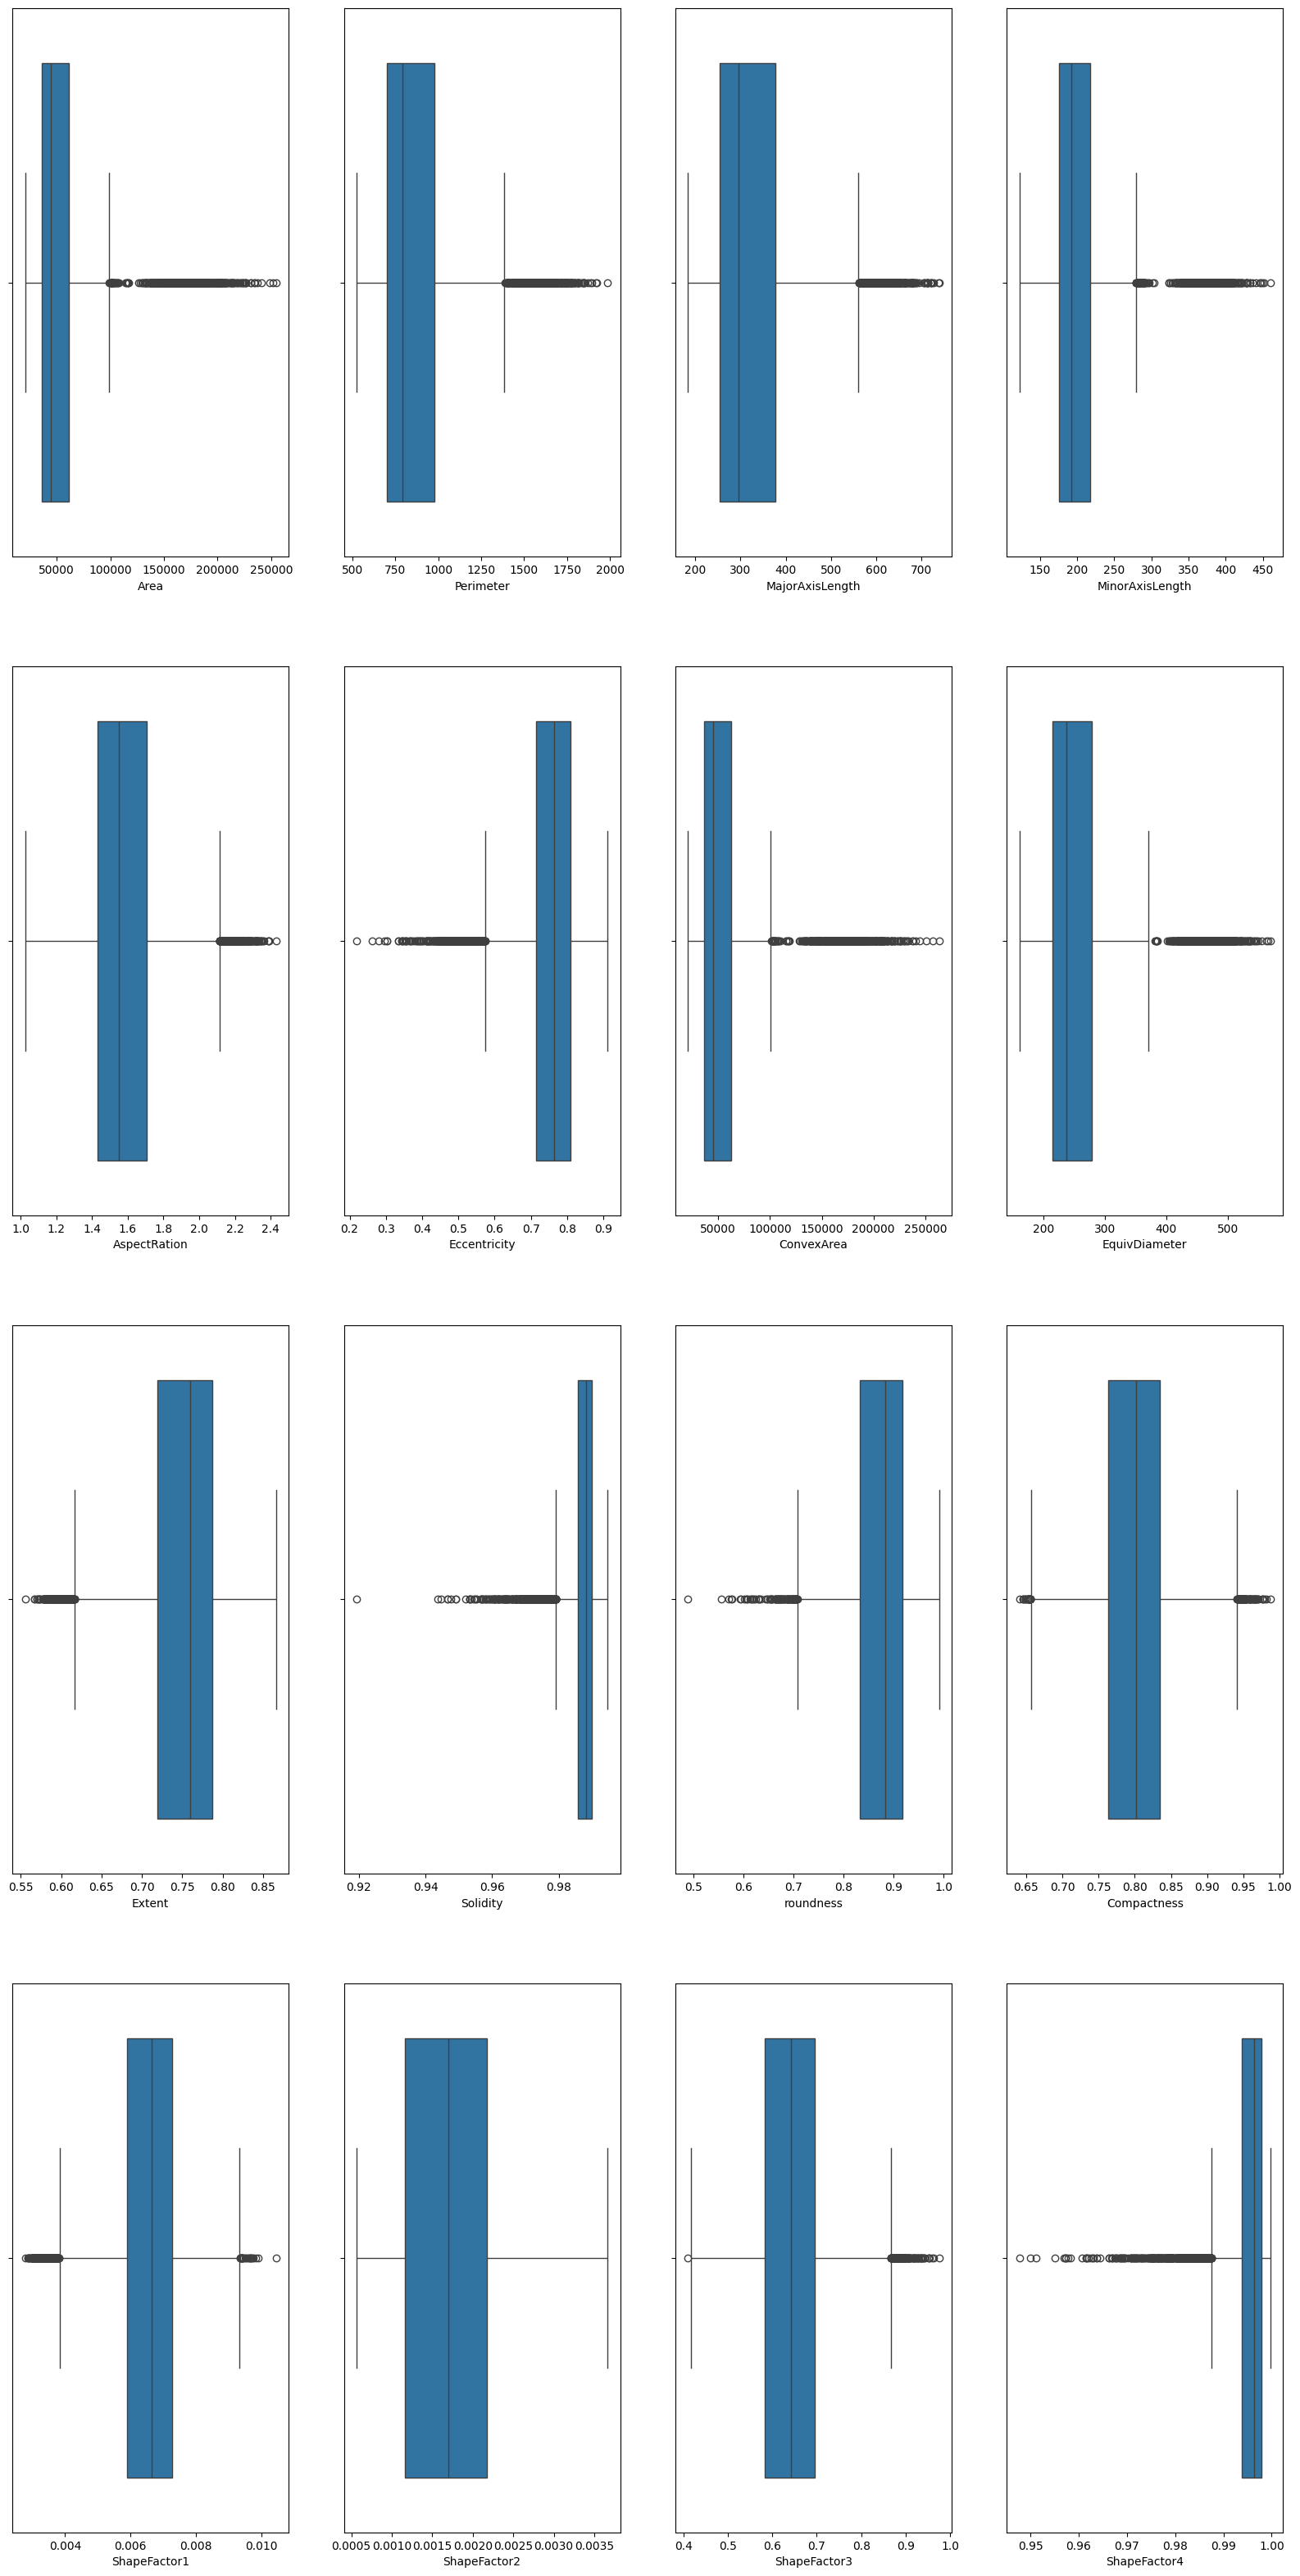

In [ ]:
# Для проверки наличий выбрасов построим диаграмму размаха
fig,ax=plt.subplots(4,4,figsize=(20,40))
ax=ax.flatten()
i=0
for col in df.columns[df.columns!='Class']:
    sns.boxplot(data=df,x=col,ax=ax[i])
    i+=1

In [ ]:
# У нас есть выбрасы
# Для этой задачи мы будем использовать межквартильный размах.
for col in df.columns[df.columns != 'Class']:
    for c in df['Class'].unique():
        class_subset = df[df['Class'] == c]
        q1 = class_subset[col].quantile(0.25)
        q3 = class_subset[col].quantile(0.75)
        iqr = q3 - q1
        lb = q1 - 1.5 * iqr
        ub = q3 + 1.5 * iqr
        df = df[(df[col] >= lb) & (df[col] <= ub) | (df['Class'] != c)]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11589 entries, 5 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             11589 non-null  int64  
 1   Perimeter        11589 non-null  float64
 2   MajorAxisLength  11589 non-null  float64
 3   MinorAxisLength  11589 non-null  float64
 4   AspectRation     11589 non-null  float64
 5   Eccentricity     11589 non-null  float64
 6   ConvexArea       11589 non-null  int64  
 7   EquivDiameter    11589 non-null  float64
 8   Extent           11589 non-null  float64
 9   Solidity         11589 non-null  float64
 10  roundness        11589 non-null  float64
 11  Compactness      11589 non-null  float64
 12  ShapeFactor1     11589 non-null  float64
 13  ShapeFactor2     11589 non-null  float64
 14  ShapeFactor3     11589 non-null  float64
 15  ShapeFactor4     11589 non-null  float64
 16  Class            11589 non-null  object 
dtypes: float64(14), i

In [ ]:
# Разделим наш датасет на целевые объекты
x=df.drop(columns="Class")
y=df["Class"]

In [ ]:
y.value_counts()

,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


In [ ]:
# У нас Таргеты не сбалансированы и для того чтобы сбалансировать используем метод SMOTE

from imblearn.over_sampling import SMOTE

smote=SMOTE(sampling_strategy="auto",random_state=20)

xr,yr=smote.fit_resample(x,y)
ndf=pd.DataFrame(xr,columns=x.columns)
ndf["Class"]=yr
print(ndf["Class"].value_counts())

Class
SEKER       3107
BARBUNYA    3107
BOMBAY      3107
CALI        3107
HOROZ       3107
SIRA        3107
DERMASON    3107
Name: count, dtype: int64


In [ ]:
# Стандартизируем наши данные
from sklearn.preprocessing import StandardScaler

ss=StandardScaler()
feature_cols = ndf.columns[ndf.columns != "Class"]
ndf[feature_cols] = ss.fit_transform(ndf[feature_cols])

In [ ]:
for col in ndf.columns[ndf.columns!="Class"]:
    print(col,'-->','Среднее: ',ndf[col].mean(),'Стандартное отклонение: ',ndf[col].std())

Area --> Среднее:  -5.22722137668932e-17 Стандартное отклонение:  1.0000229903555478
Perimeter --> Среднее:  -3.7635993912163107e-16 Стандартное отклонение:  1.0000229903555486
MajorAxisLength --> Среднее:  4.181777101351456e-16 Стандартное отклонение:  1.0000229903555515
MinorAxisLength --> Среднее:  3.1363328260135924e-16 Стандартное отклонение:  1.00002299035555
AspectRation --> Среднее:  6.272665652027184e-17 Стандартное отклонение:  1.000022990355551
Eccentricity --> Среднее:  3.3715577879646116e-16 Стандартное отклонение:  1.0000229903555502
ConvexArea --> Среднее:  -6.272665652027184e-17 Стандартное отклонение:  1.000022990355547
EquivDiameter --> Среднее:  2.090888550675728e-16 Стандартное отклонение:  1.0000229903555524
Extent --> Среднее:  1.9863441231419417e-16 Стандартное отклонение:  1.000022990355549
Solidity --> Среднее:  2.5038390394341846e-15 Стандартное отклонение:  1.000022990355547
roundness --> Среднее:  -1.777255268074369e-15 Стандартное отклонение:  1.00002299035

In [ ]:
# Закодируем наши классы в числа

from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
ndf["Class"]=le.fit_transform(ndf["Class"])
ndf["Class"].value_counts()

,count
Class,
5,3107
0,3107
1,3107
2,3107
4,3107
6,3107
3,3107


In [ ]:
ndf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21749 entries, 0 to 21748
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             21749 non-null  float64
 1   Perimeter        21749 non-null  float64
 2   MajorAxisLength  21749 non-null  float64
 3   MinorAxisLength  21749 non-null  float64
 4   AspectRation     21749 non-null  float64
 5   Eccentricity     21749 non-null  float64
 6   ConvexArea       21749 non-null  float64
 7   EquivDiameter    21749 non-null  float64
 8   Extent           21749 non-null  float64
 9   Solidity         21749 non-null  float64
 10  roundness        21749 non-null  float64
 11  Compactness      21749 non-null  float64
 12  ShapeFactor1     21749 non-null  float64
 13  ShapeFactor2     21749 non-null  float64
 14  ShapeFactor3     21749 non-null  float64
 15  ShapeFactor4     21749 non-null  float64
 16  Class            21749 non-null  int64  
dtypes: float64(1

In [ ]:
from sklearn.feature_selection import mutual_info_classif

In [ ]:
# вычисление взаимной информации

x = ndf.drop(columns="Class")
y = ndf["Class"]
mi=mutual_info_classif(x,y)
mi_df=pd.DataFrame({'Взаимная информация':mi,'Признаки':x.columns})
mi_df.sort_values(by='Взаимная информация',ascending=False,inplace=True)

In [ ]:
mi_df

,Mutual Information,Features
6,1.331053,ConvexArea
7,1.324929,EquivDiameter
0,1.324425,Area
1,1.289884,Perimeter
2,1.232719,MajorAxisLength
13,1.190799,ShapeFactor2
3,1.168341,MinorAxisLength
12,1.165438,ShapeFactor1
10,0.999008,roundness
14,0.985725,ShapeFactor3


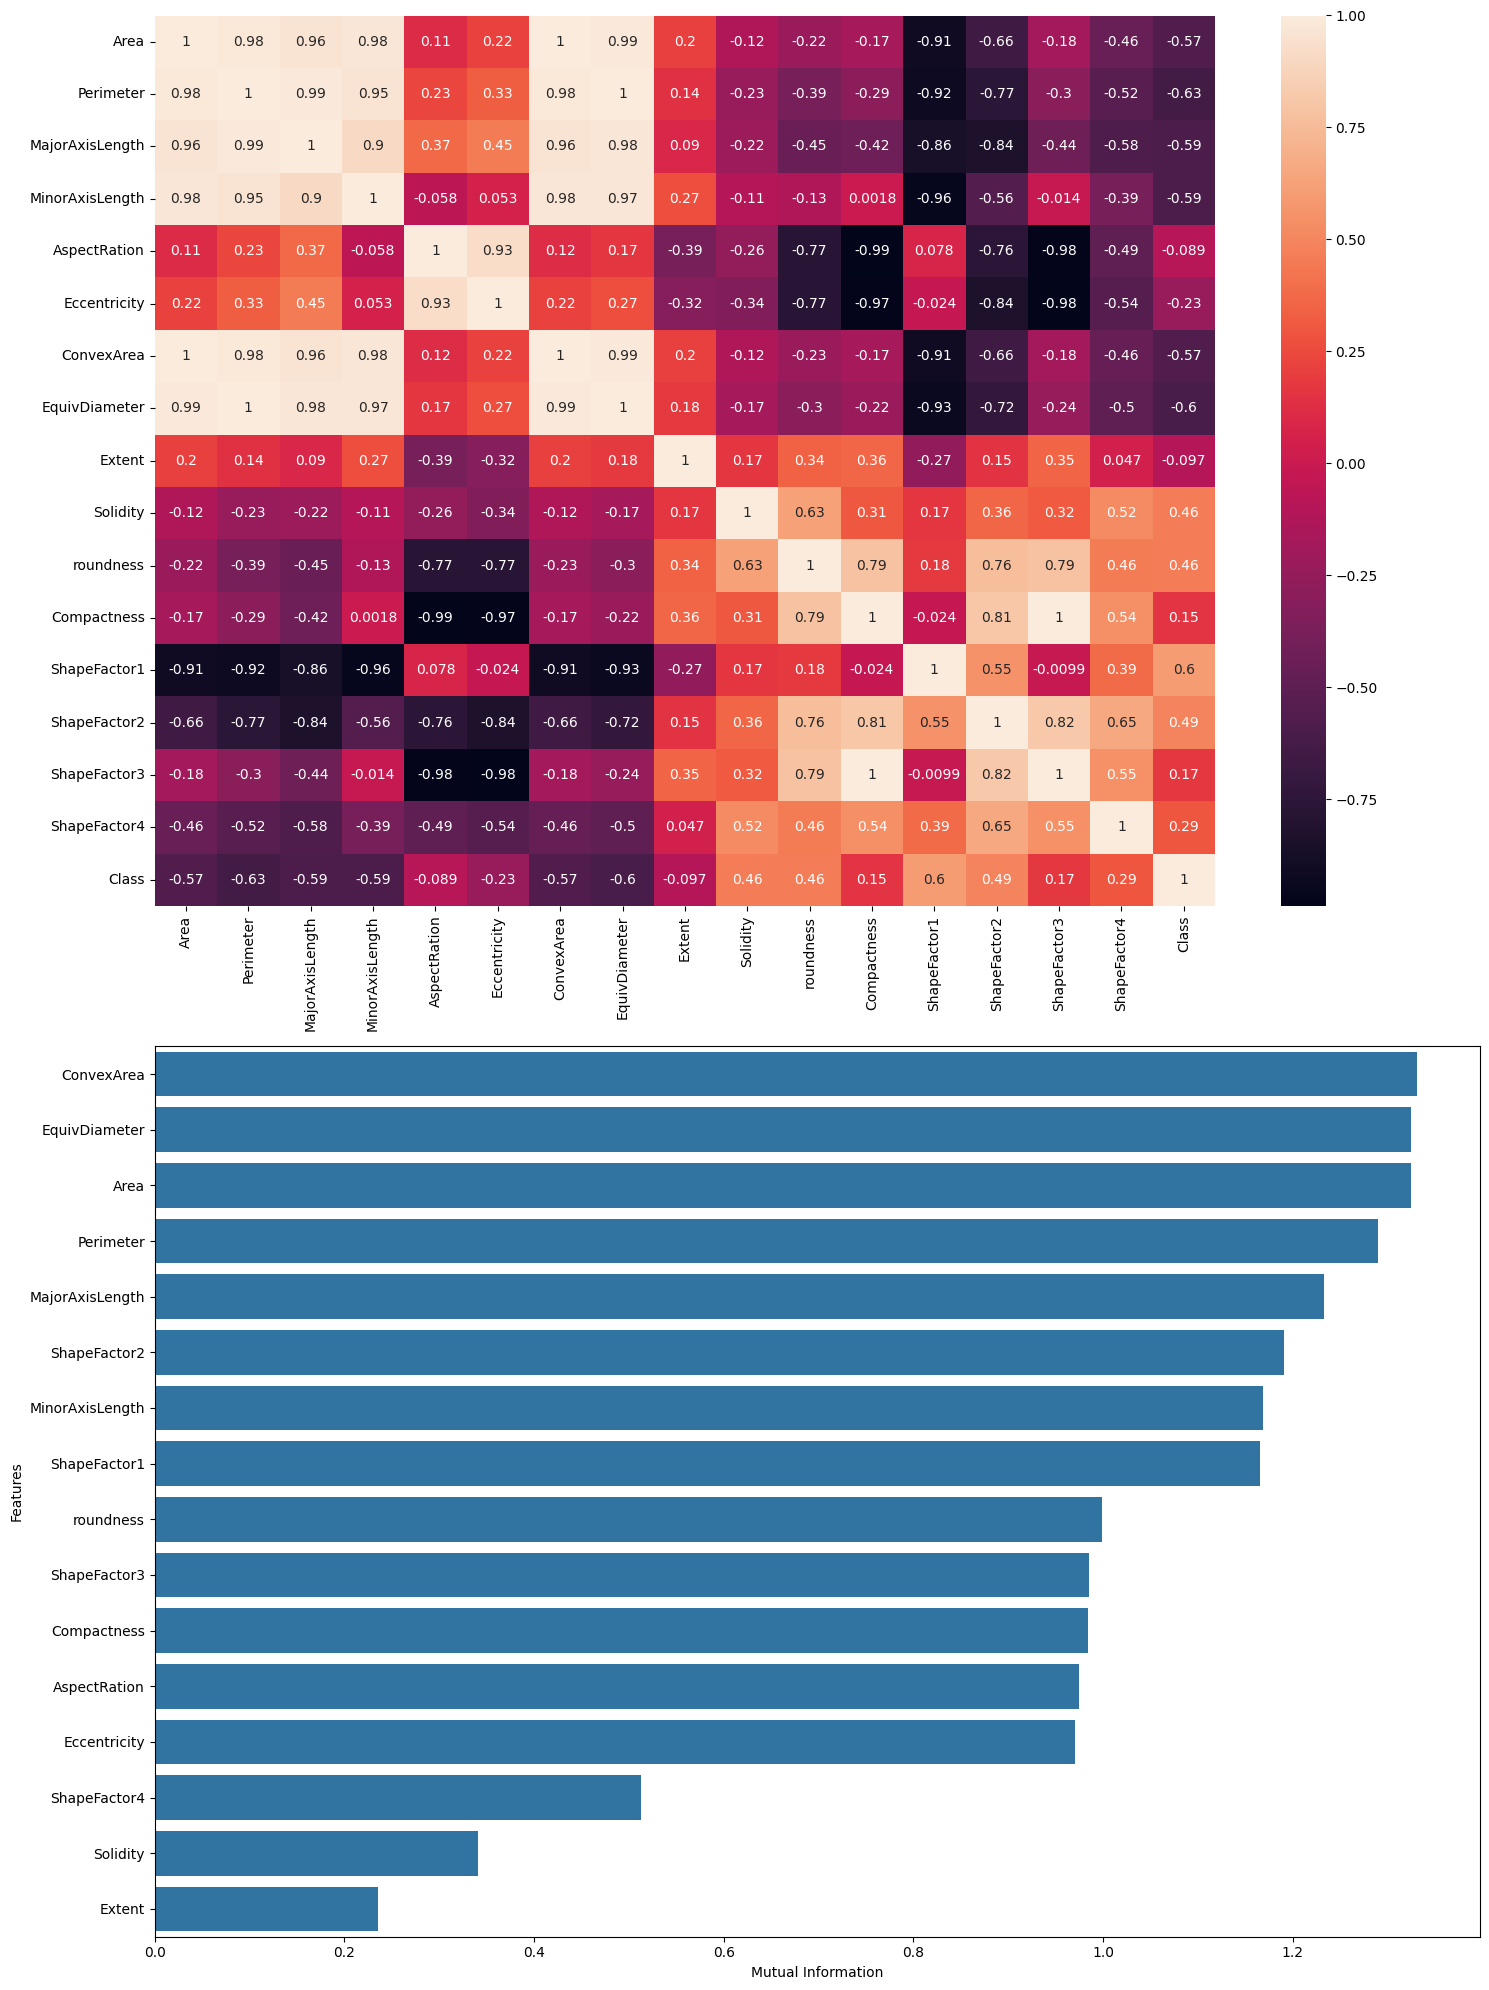

In [ ]:
# строим матрица корреляции и гистограмму взаимной информации

fig,ax=plt.subplots(2,1,figsize=(15,20))
sns.heatmap(ndf.corr(),annot=True,ax=ax[0])
sns.barplot(data=mi_df,x='Mutual Information',y='Features')
plt.tight_layout()
plt.show()

In [ ]:
# делим датасет на тестовый и тренировочный данные 20 на 80
from sklearn.model_selection import train_test_split

X = ndf.drop(columns="Class")
y = ndf["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=20, test_size=0.2, stratify=y)

In [ ]:
# Загружаем модели которые нужно обучить на нашей выборке

from mlxtend.classifier import OneRClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.svm import LinearSVC

In [ ]:
# Модель One Rule обучение на выборке

One_r = OneRClassifier()
One_r.fit(X_train.values, y_train.values)
pred_one = One_r.predict(X_test.values)

In [ ]:
# Модель Логистической регрессии обучение на выборке

Log_r = LogisticRegression(max_iter=1000)
Log_r.fit(X_train.values, y_train.values)
pred_log = Log_r.predict(X_test.values)

In [ ]:
# Модель К ближайших соседей обучение на выборке

KN_c = KNeighborsClassifier(n_neighbors=5)
KN_c.fit(X_train.values, y_train.values)
pred_KN = KN_c.predict(X_test.values)

In [ ]:
# Модель Наивный байесовский классификатор обучение на выборке

GNB = GaussianNB()
GNB.fit(X_train.values, y_train.values)
pred_GNB = GNB.predict(X_test.values)

In [ ]:
# Модель Деревья решения на выборке

D_tree = DecisionTreeClassifier(random_state=20)
D_tree.fit(X_train.values, y_train.values)
pred_D_tree = D_tree.predict(X_test.values)

In [ ]:
# Модель градиентный бустинг обучение на выборке

GB_c = GradientBoostingClassifier(random_state=20)
GB_c.fit(X_train.values, y_train.values)
pred_GB = GB_c.predict(X_test.values)

In [ ]:
# Модель Метод опорных векторов обучение на выборке

svc = SVC()
svc.fit(X_train.values, y_train.values)
pred_svc = svc.predict(X_test.values)

In [ ]:
svm = LinearSVC()
svm.fit(X_train.values, y_train.values)
pred_svm = svc.predict(X_test.values)

In [ ]:
# Модель Полносвязная нейронная сеть обучение на выборке

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=500,
    random_state=20
)

mlp.fit(X_train, y_train)
pred_mlp = mlp.predict(X_test)

In [ ]:
# Модель Ансамбль моделей обучение на выборке.
# Использовал 4 модели Логистическую регрессию, К ближайших соседей, Деревья решений, Градиентный бустинг

ensemble = VotingClassifier(
    estimators=[
        ("lr", Log_r),
        ("knn", KN_c),
        ("tree", D_tree),
        ("gb", GB_c)
    ],
    voting="hard"
)

ensemble.fit(X_train, y_train)
pred_ensemble = ensemble.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

results = pd.DataFrame({
    "Model": ["OneR", "Logistic Regression", "KNN", "Naive Bayes", "Decision Tree", "Gradient Boosting", "SVC", "SVM", "MLP", "Ensemble"],
    "Accuracy": [
        accuracy_score(y_test, pred_one),
        accuracy_score(y_test, pred_log),
        accuracy_score(y_test, pred_KN),
        accuracy_score(y_test, pred_GNB),
        accuracy_score(y_test, pred_D_tree),
        accuracy_score(y_test, pred_GB),
        accuracy_score(y_test, pred_svc),
        accuracy_score(y_test, pred_svm),
        accuracy_score(y_test, pred_mlp),
        accuracy_score(y_test, pred_ensemble)
    ],
    "F1-score": [
        f1_score(y_test, pred_one, average="weighted"),
        f1_score(y_test, pred_log, average="weighted"),
        f1_score(y_test, pred_KN, average="weighted"),
        f1_score(y_test, pred_GNB, average="weighted"),
        f1_score(y_test, pred_D_tree, average="weighted"),
        f1_score(y_test, pred_GB, average="weighted"),
        f1_score(y_test, pred_svc, average="weighted"),
        f1_score(y_test, pred_svm, average="weighted"),
        f1_score(y_test, pred_mlp, average="weighted"),
        f1_score(y_test, pred_ensemble, average="weighted")
    ],
    "Precision": [
        precision_score(y_test, pred_one, average="weighted"),
        precision_score(y_test, pred_log, average="weighted"),
        precision_score(y_test, pred_KN, average="weighted"),
        precision_score(y_test, pred_GNB, average="weighted"),
        precision_score(y_test, pred_D_tree, average="weighted"),
        precision_score(y_test, pred_GB, average="weighted"),
        precision_score(y_test, pred_svc, average="weighted"),
        precision_score(y_test, pred_svm, average="weighted"),
        precision_score(y_test, pred_mlp, average="weighted"),
        precision_score(y_test, pred_ensemble, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, pred_one, average="weighted"),
        recall_score(y_test, pred_log, average="weighted"),
        recall_score(y_test, pred_KN, average="weighted"),
        recall_score(y_test, pred_GNB, average="weighted"),
        recall_score(y_test, pred_D_tree, average="weighted"),
        recall_score(y_test, pred_GB, average="weighted"),
        recall_score(y_test, pred_svc, average="weighted"),
        recall_score(y_test, pred_svm, average="weighted"),
        recall_score(y_test, pred_mlp, average="weighted"),
        recall_score(y_test, pred_ensemble, average="weighted")
    ]
})

print(results.sort_values(by="Accuracy", ascending=False))

                 Model  Accuracy  F1-score  Precision    Recall
5    Gradient Boosting  0.972874  0.972914   0.973092  0.972874
6                  SVC  0.972184  0.972238   0.972464  0.972184
7                  SVM  0.972184  0.972238   0.972464  0.972184
8                  MLP  0.970345  0.970385   0.970776  0.970345
9             Ensemble  0.970115  0.970171   0.970325  0.970115
1  Logistic Regression  0.969425  0.969470   0.969688  0.969425
2                  KNN  0.967816  0.967855   0.968261  0.967816
4        Decision Tree  0.963218  0.963257   0.963340  0.963218
3          Naive Bayes  0.949655  0.949735   0.950646  0.949655
0                 OneR  0.142759  0.035668   0.020380  0.142759


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Как мы видим модели все выдают точность больше 0.9, кроме One Rule. Так как он выбирает один признак и по нему классифицирует.




In [ ]:
importance_GB = pd.DataFrame({
    "Feature": X.columns,
    "Importance": GB_c.feature_importances_
})

importance_GB = importance_GB.sort_values(
    by="Importance",
    ascending=False
)

print(importance_GB)

print("\n")
print("+" * 50)
print("\n")

importance_tree = pd.DataFrame({
    "Feature": X.columns,
    "Importance": D_tree.feature_importances_
})

importance_tree = importance_tree.sort_values(
    by="Importance",
    ascending=False
)

print(importance_tree)


            Feature  Importance
14     ShapeFactor3    0.186278
5      Eccentricity    0.152285
1         Perimeter    0.101258
3   MinorAxisLength    0.099054
2   MajorAxisLength    0.065068
7     EquivDiameter    0.057107
15     ShapeFactor4    0.056407
0              Area    0.051506
12     ShapeFactor1    0.049407
13     ShapeFactor2    0.043189
9          Solidity    0.036840
11      Compactness    0.034835
10        roundness    0.033757
6        ConvexArea    0.028361
4      AspectRation    0.003861
8            Extent    0.000789
++++++++++++++++++++++++++++++++++++++++++++++++++
            Feature  Importance
1         Perimeter    0.287108
14     ShapeFactor3    0.246848
3   MinorAxisLength    0.181778
5      Eccentricity    0.156825
10        roundness    0.050298
15     ShapeFactor4    0.019822
9          Solidity    0.013523
12     ShapeFactor1    0.013022
13     ShapeFactor2    0.007631
8            Extent    0.005428
11      Compactness    0.004991
7     EquivDiameter  

По важности признаков в датасете, видим что Gradient boosting и Decision Tree наиболее важными признаками оказались ShapeFactor3, Perimeter, Eccentricity, MinorAxisLength. Признаки оказывают наибольшее влияние на качество классификации.

In [ ]:
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": Log_r.coef_[0]
})

coef["Abs"] = coef["Coefficient"].abs()

coef = coef.sort_values(by="Abs", ascending=False)

print(coef)

print("\n")
print("+" * 50)
print("\n")

coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": svm.coef_[0]
})

coef["Abs"] = coef["Coefficient"].abs()

coef = coef.sort_values(by="Abs", ascending=False)

print(coef)


            Feature  Coefficient       Abs
10        roundness    -4.281006  4.281006
12     ShapeFactor1    -2.529604  2.529604
1         Perimeter     1.872574  1.872574
15     ShapeFactor4     1.656278  1.656278
3   MinorAxisLength     1.580876  1.580876
4      AspectRation    -1.392875  1.392875
11      Compactness     1.389784  1.389784
14     ShapeFactor3     1.343770  1.343770
7     EquivDiameter     1.265776  1.265776
9          Solidity    -1.236557  1.236557
5      Eccentricity    -1.048245  1.048245
2   MajorAxisLength     0.886901  0.886901
6        ConvexArea     0.856436  0.856436
0              Area     0.852100  0.852100
13     ShapeFactor2    -0.447302  0.447302
8            Extent     0.052618  0.052618


++++++++++++++++++++++++++++++++++++++++++++++++++


            Feature  Coefficient       Abs
13     ShapeFactor2    -4.216882  4.216882
12     ShapeFactor1    -3.685174  3.685174
4      AspectRation    -2.229352  2.229352
6        ConvexArea    -2.109415  2.109415

В Logistic Regression также подтвердила высокую значимость признаков roundness, ShapeFactor1, Perimeter и ShapeFactor4. Большие значения коэффициентов по модулю свидетельствуют о сильном влиянии данных признаков на вероятность принадлежности объекта к определённому классу.

Наименее информативными признаками оказались Extent и AspectRation, поскольку их вклад в итоговое предсказание оказался минимальным.

In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
result_knn = permutation_importance(
    KN_c,
    X_test,
    y_test,
    n_repeats=10,
    random_state=20
)

importance_knn = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result_knn.importances_mean
})

importance_knn = importance_knn.sort_values(
    by="Importance",
    ascending=False
)

print(importance_knn)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning

            Feature  Importance
15     ShapeFactor4    0.096920
12     ShapeFactor1    0.080368
10        roundness    0.073816
5      Eccentricity    0.035471
4      AspectRation    0.031448
1         Perimeter    0.029655
14     ShapeFactor3    0.029609
3   MinorAxisLength    0.029264
11      Compactness    0.028322
9          Solidity    0.027011
7     EquivDiameter    0.025563
13     ShapeFactor2    0.024966
2   MajorAxisLength    0.022368
0              Area    0.012782
6        ConvexArea    0.012575
8            Extent    0.008552


В модели K-ближайших соседей значимыми признаками является ShapeFactor4, ShapeFactor1, roundness

In [ ]:
result_svm = permutation_importance(
    svm,
    X_test,
    y_test,
    n_repeats=10,
    random_state=20
)

importance_svm = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result_svm.importances_mean
})

importance_svm = importance_svm.sort_values(
    by="Importance",
    ascending=False
)

print(importance_svm)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearSVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearSVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearSVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearSVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearSVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearSVC was fitted without

            Feature  Importance
12     ShapeFactor1    0.422069
5      Eccentricity    0.279563
13     ShapeFactor2    0.274989
1         Perimeter    0.248391
4      AspectRation    0.242345
6        ConvexArea    0.171333
0              Area    0.165011
14     ShapeFactor3    0.127402
3   MinorAxisLength    0.118529
10        roundness    0.105908
2   MajorAxisLength    0.100690
11      Compactness    0.082437
15     ShapeFactor4    0.053977
7     EquivDiameter    0.043149
9          Solidity    0.000621
8            Extent    0.000046


В модели SVM значимыми признаками является ShapeFactor1, Eccentricity, ShapeFactor2

In [ ]:
result_mlp = permutation_importance(
    mlp,
    X_test,
    y_test,
    n_repeats=10,
    random_state=20
)

importance_mlp = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result_mlp.importances_mean
})

importance_mlp = importance_mlp.sort_values(
    by="Importance",
    ascending=False
)

print(importance_mlp)

            Feature  Importance
12     ShapeFactor1    0.169218
10        roundness    0.137126
13     ShapeFactor2    0.131770
5      Eccentricity    0.084184
15     ShapeFactor4    0.080782
4      AspectRation    0.068598
11      Compactness    0.049701
6        ConvexArea    0.045034
3   MinorAxisLength    0.030690
14     ShapeFactor3    0.028506
1         Perimeter    0.022391
0              Area    0.021379
2   MajorAxisLength    0.019563
9          Solidity    0.017724
7     EquivDiameter    0.016920
8            Extent    0.004345


В модели MLP значимыми признаками является ShapeFactor1, roundness, ShapeFactor2

In [ ]:
result_ens = permutation_importance(
    ensemble,
    X_test,
    y_test,
    n_repeats=10,
    random_state=20
)

importance_ens = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result_ens.importances_mean
})

importance_ens = importance_ens.sort_values(
    by="Importance",
    ascending=False
)

print(importance_ens)

            Feature  Importance
5      Eccentricity    0.095494
15     ShapeFactor4    0.087747
10        roundness    0.057402
14     ShapeFactor3    0.025931
12     ShapeFactor1    0.024368
1         Perimeter    0.019517
3   MinorAxisLength    0.018391
11      Compactness    0.016414
4      AspectRation    0.014322
9          Solidity    0.010621
13     ShapeFactor2    0.008483
2   MajorAxisLength    0.007563
7     EquivDiameter    0.006023
0              Area    0.003655
6        ConvexArea    0.003402
8            Extent    0.001149


В модели Ансамбль значимыми признаками является Eccentricity, ShapeFactor4, roundness
